In [1]:
import os
import mne
import pandas as pd
import matplotlib.pyplot as plt
from mne.preprocessing import ICA
from mne_icalabel import label_components

In [2]:
# 기본 경로 설정
base_path = "D:/Users/windows/Desktop/Inner Speech Decoding/Dataset/"

In [3]:
# 피험자 번호 설정
subject = "sub-02"

In [4]:
file_path = f"{base_path}/{subject}_ses-01_task-innerspeech_eeg.bdf"

raw = mne.io.read_raw_bdf(file_path, preload=True, verbose="WARNING")
raw

<RawEDF | sub-02_ses-01_task-innerspeech_eeg.bdf, 137 x 1670144 (1631.0 s), ~1.70 GiB, data loaded>

In [5]:
channels = raw.info['ch_names']
channels

['A1',
 'A2',
 'A3',
 'A4',
 'A5',
 'A6',
 'A7',
 'A8',
 'A9',
 'A10',
 'A11',
 'A12',
 'A13',
 'A14',
 'A15',
 'A16',
 'A17',
 'A18',
 'A19',
 'A20',
 'A21',
 'A22',
 'A23',
 'A24',
 'A25',
 'A26',
 'A27',
 'A28',
 'A29',
 'A30',
 'A31',
 'A32',
 'B1',
 'B2',
 'B3',
 'B4',
 'B5',
 'B6',
 'B7',
 'B8',
 'B9',
 'B10',
 'B11',
 'B12',
 'B13',
 'B14',
 'B15',
 'B16',
 'B17',
 'B18',
 'B19',
 'B20',
 'B21',
 'B22',
 'B23',
 'B24',
 'B25',
 'B26',
 'B27',
 'B28',
 'B29',
 'B30',
 'B31',
 'B32',
 'C1',
 'C2',
 'C3',
 'C4',
 'C5',
 'C6',
 'C7',
 'C8',
 'C9',
 'C10',
 'C11',
 'C12',
 'C13',
 'C14',
 'C15',
 'C16',
 'C17',
 'C18',
 'C19',
 'C20',
 'C21',
 'C22',
 'C23',
 'C24',
 'C25',
 'C26',
 'C27',
 'C28',
 'C29',
 'C30',
 'C31',
 'C32',
 'D1',
 'D2',
 'D3',
 'D4',
 'D5',
 'D6',
 'D7',
 'D8',
 'D9',
 'D10',
 'D11',
 'D12',
 'D13',
 'D14',
 'D15',
 'D16',
 'D17',
 'D18',
 'D19',
 'D20',
 'D21',
 'D22',
 'D23',
 'D24',
 'D25',
 'D26',
 'D27',
 'D28',
 'D29',
 'D30',
 'D31',
 'D32',
 'EXG1',
 'E

In [6]:
# BioSemi 128 montage 불러오기
montage = mne.channels.make_standard_montage('biosemi128')

# montage 적용
raw.set_montage(montage, on_missing='ignore')  # EXG 채널은 위치 정보 없이 유지하고, EEG 채널만 montage를 적용

<RawEDF | sub-02_ses-01_task-innerspeech_eeg.bdf, 137 x 1670144 (1631.0 s), ~1.70 GiB, data loaded>

In [7]:
# montage 정보 출력
print(raw.get_montage())

<DigMontage | 0 extras (headshape), 0 HPIs, 3 fiducials, 136 channels>


In [8]:
print(raw.info['dig'])     # 빈 리스트([])면 안됨

[<DigPoint |        LPA : (-86.1, -0.0, 0.0) mm     : head frame>, <DigPoint |     Nasion : (0.0, 86.1, 0.0) mm       : head frame>, <DigPoint |        RPA : (86.1, 0.0, 0.0) mm       : head frame>, <DigPoint |     EEG #1 : (0.0, 0.0, 135.1) mm      : head frame>, <DigPoint |     EEG #2 : (0.0, -18.1, 133.4) mm    : head frame>, <DigPoint |     EEG #3 : (0.0, -37.1, 127.6) mm    : head frame>, <DigPoint |     EEG #4 : (0.0, -53.1, 118.9) mm    : head frame>, <DigPoint |     EEG #5 : (-26.7, -62.9, 106.1) mm  : head frame>, <DigPoint |     EEG #6 : (-48.3, -48.3, 106.1) mm  : head frame>, <DigPoint |     EEG #7 : (-56.3, -56.3, 91.9) mm   : head frame>, <DigPoint |     EEG #8 : (-52.1, -71.8, 74.2) mm   : head frame>, <DigPoint |     EEG #9 : (-55.0, -75.7, 56.6) mm   : head frame>, <DigPoint |    EEG #10 : (-55.8, -76.8, 36.8) mm   : head frame>, <DigPoint |    EEG #11 : (-54.4, -74.9, 18.8) mm   : head frame>, <DigPoint |    EEG #12 : (-50.6, -69.7, 0.0) mm    : head frame>, <DigPoint

In [9]:
events = mne.find_events(raw, shortest_event=1, verbose=True)

Trigger channel Status has a non-zero initial value of 65536 (consider using initial_event=True to detect this event)
Removing orphaned offset at the beginning of the file.
1044 events found on stim channel Status
Event IDs: [11 12 13 14 15 16 17 21 22 23 31 32 33 34 42 44 45 46 51 61 62 63 64]


In [10]:
print(events)

[[   8394       0      11]
 [  18702       0      13]
 [  34080       0      14]
 ...
 [1631967       0      46]
 [1631998       0      16]
 [1632040       0      12]]


In [11]:
# Re-referencing
raw.set_eeg_reference(ref_channels=['EXG1', 'EXG2'])

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.


<RawEDF | sub-02_ses-01_task-innerspeech_eeg.bdf, 137 x 1670144 (1631.0 s), ~1.70 GiB, data loaded>

In [12]:
eeg_d = raw.get_data()
eeg_d

array([[ 3.26761271e-02,  3.26739396e-02,  3.26721271e-02, ...,
         1.41637551e-02,  1.41569426e-02,  1.41601770e-02],
       [ 3.02218817e-02,  3.02201004e-02,  3.02187567e-02, ...,
         1.49022225e-02,  1.48964412e-02,  1.48993318e-02],
       [ 2.90465088e-02,  2.90445713e-02,  2.90434151e-02, ...,
         1.39581617e-02,  1.39522555e-02,  1.39553961e-02],
       ...,
       [-2.43612050e-03, -2.43840174e-03, -2.43937049e-03, ...,
        -2.89749465e-04, -2.90936962e-04, -2.89640090e-04],
       [-1.42541612e-02, -1.42560674e-02, -1.42557862e-02, ...,
        -1.26901953e-02, -1.26856953e-02, -1.26779297e-02],
       [ 6.55360000e+04,  6.55360000e+04,  6.55360000e+04, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00]])

In [13]:
eeg_d.shape

(137, 1670144)

In [14]:
channel_names = raw.ch_names

# NumPy 배열을 DataFrame으로 변환
df = pd.DataFrame(eeg_d.T, columns=channel_names)
df

,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10,...,D32,EXG1,EXG2,EXG3,EXG4,EXG5,EXG6,EXG7,EXG8,Status
0,0.032676,0.030222,0.029047,0.024414,-0.000907,-0.005674,0.006557,0.003604,0.002052,-0.001573,...,0.006787,-0.006256,0.006256,-0.010050,-0.003267,0.001121,0.007404,-0.002436,-0.014254,65536.0
1,0.032674,0.030220,0.029045,0.024411,-0.000893,-0.005677,0.006554,0.003602,0.002051,-0.001574,...,0.006786,-0.006255,0.006255,-0.010048,-0.003270,0.001121,0.007404,-0.002438,-0.014256,65536.0
2,0.032672,0.030219,0.029043,0.024410,-0.000893,-0.005676,0.006553,0.003603,0.002050,-0.001573,...,0.006785,-0.006254,0.006254,-0.010046,-0.003271,0.001123,0.007405,-0.002439,-0.014256,65536.0
3,0.032671,0.030218,0.029042,0.024409,-0.000898,-0.005675,0.006554,0.003602,0.002050,-0.001574,...,0.006783,-0.006253,0.006253,-0.010046,-0.003270,0.001126,0.007404,-0.002439,-0.014253,65536.0
4,0.032669,0.030218,0.029041,0.024409,-0.000914,-0.005678,0.006550,0.003601,0.002048,-0.001574,...,0.006782,-0.006254,0.006254,-0.010049,-0.003270,0.001125,0.007402,-0.002438,-0.014249,65536.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1670139,0.014175,0.014912,0.013968,0.014376,-0.000391,-0.006776,0.004699,0.003917,0.003230,0.003240,...,0.006656,-0.006224,0.006224,-0.004101,-0.002590,0.004014,0.008795,-0.000297,-0.012689,0.0
1670140,0.014171,0.014909,0.013965,0.014373,-0.000403,-0.006782,0.004693,0.003914,0.003225,0.003239,...,0.006652,-0.006224,0.006224,-0.004100,-0.002583,0.004013,0.008802,-0.000292,-0.012687,0.0
1670141,0.014164,0.014902,0.013958,0.014367,-0.000408,-0.006793,0.004679,0.003900,0.003212,0.003226,...,0.006635,-0.006223,0.006223,-0.004094,-0.002581,0.004012,0.008810,-0.000290,-0.012690,0.0
1670142,0.014157,0.014896,0.013952,0.014360,-0.000410,-0.006800,0.004667,0.003884,0.003197,0.003211,...,0.006620,-0.006223,0.006223,-0.004093,-0.002588,0.004005,0.008813,-0.000291,-0.012686,0.0


Using matplotlib as 2D backend.


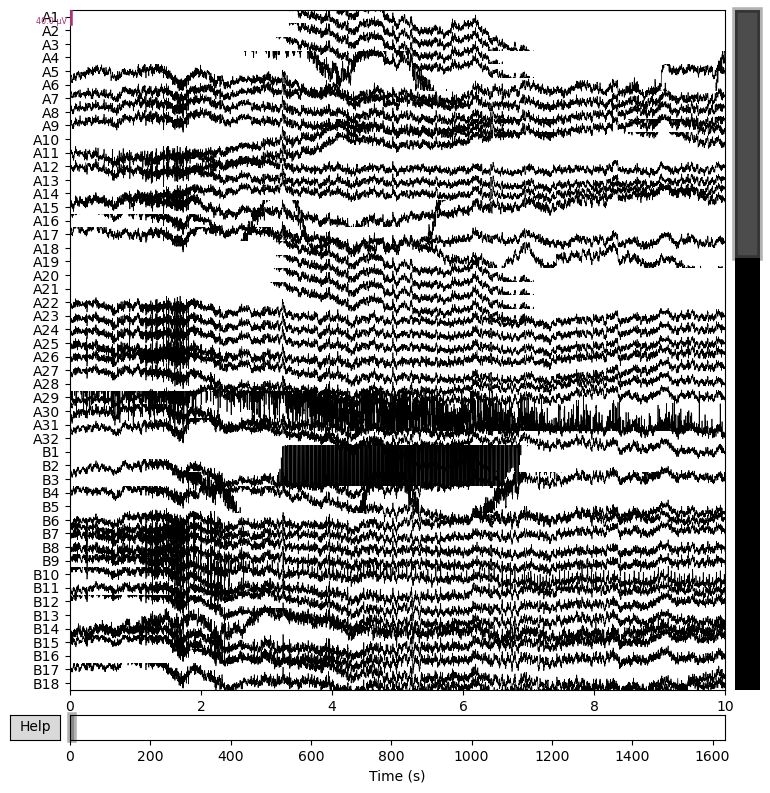

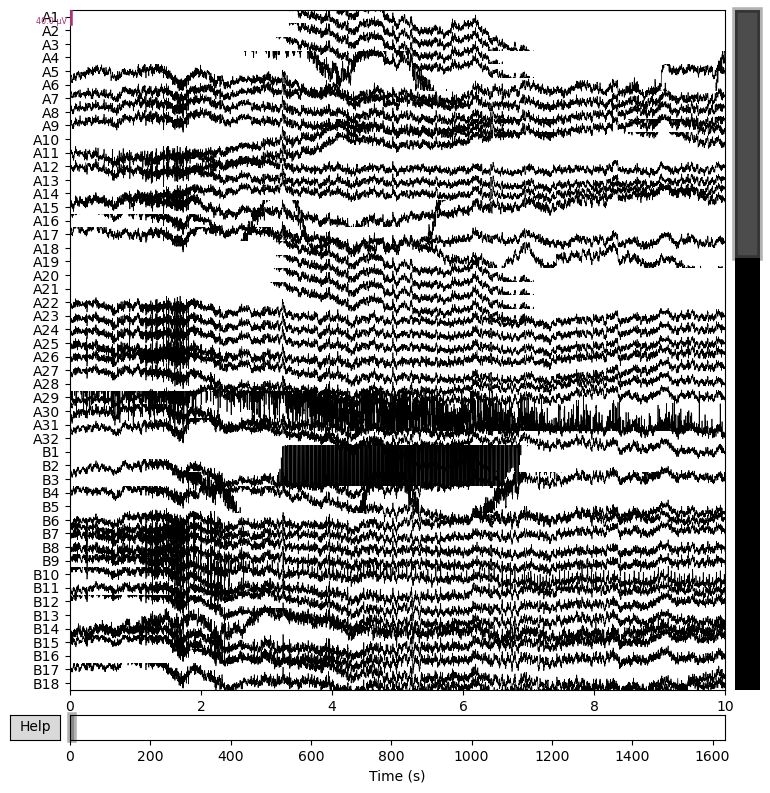

In [15]:
raw.plot(n_channels=50, title='EEG Raw Data (first 50 channels)')

In [16]:
# 0.5-100Hz Band-pass filter 적용
raw_bandpass = raw.filter(l_freq=0.5, h_freq=100)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 1e+02 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 100.00 Hz
- Upper transition bandwidth: 25.00 Hz (-6 dB cutoff frequency: 112.50 Hz)
- Filter length: 6759 samples (6.601 s)



[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    0.3s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    0.5s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   4 out of   4 | elapsed:    0.6s remaining:    0.0s
[Parallel(n_jobs=1)]: Done 136 out of 136 | elapsed:   25.1s finished


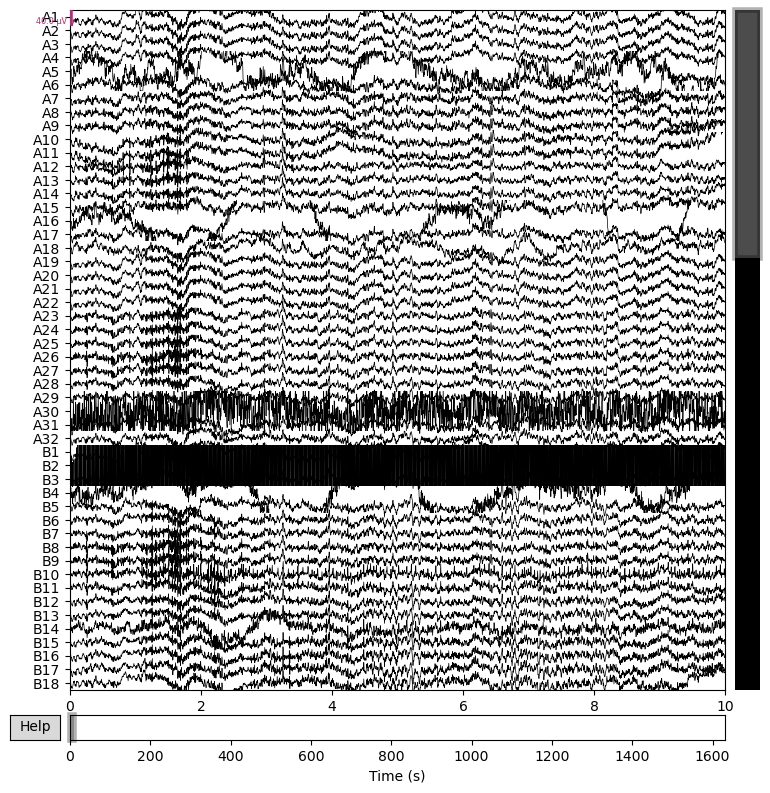

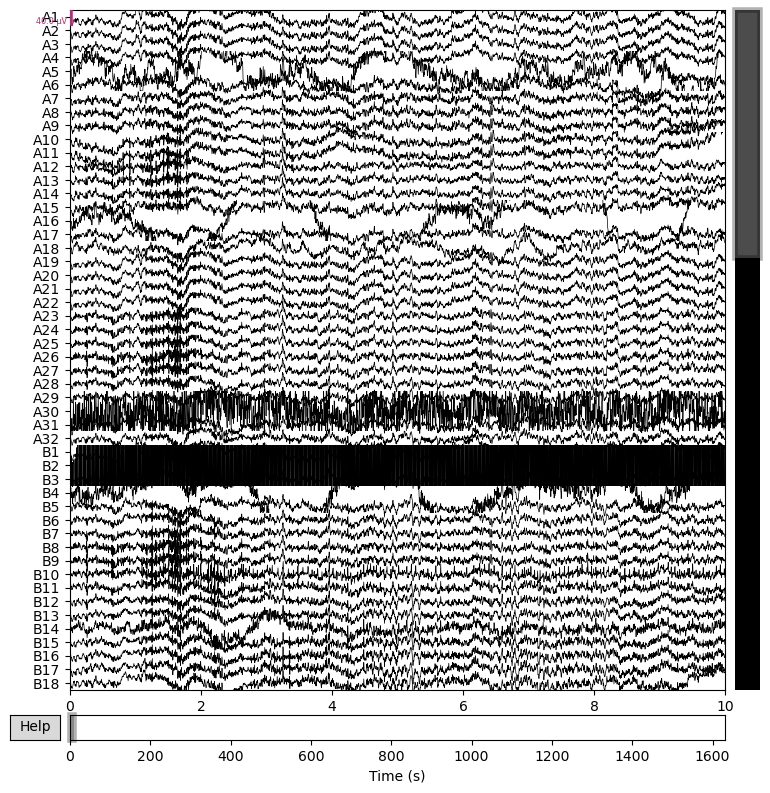

In [17]:
raw_bandpass.plot(n_channels=50, title='Filtered EEG Data (0.5-100 Hz)', show=True)

Effective window size : 2.000 (s)
Plotting power spectral density (dB=True).


C:\Users\windows\anaconda3\Lib\site-packages\mne\viz\utils.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


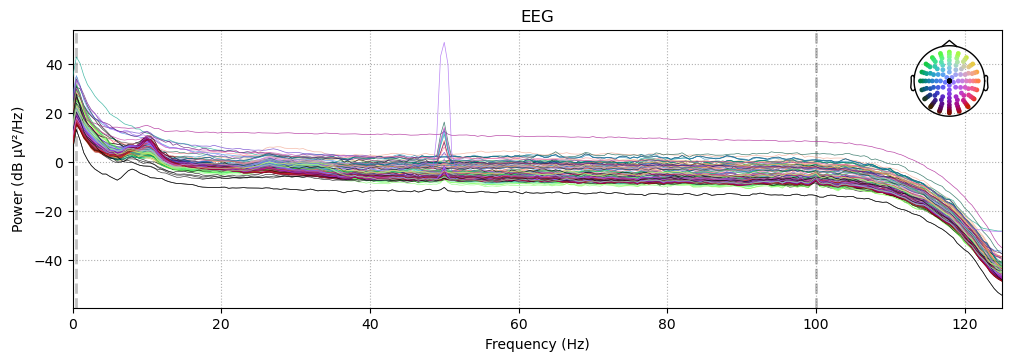

In [18]:
psd = raw_bandpass.compute_psd(fmax=125)
psd.plot()

In [19]:
# 50 Hz Notch-filter 적용
raw_notch = raw_bandpass.notch_filter(freqs=50)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 49 - 51 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 49.38
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 49.12 Hz)
- Upper passband edge: 50.62 Hz
- Upper transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 50.88 Hz)
- Filter length: 6759 samples (6.601 s)



[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    0.2s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    0.4s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   4 out of   4 | elapsed:    0.5s remaining:    0.0s
[Parallel(n_jobs=1)]: Done 136 out of 136 | elapsed:   25.2s finished


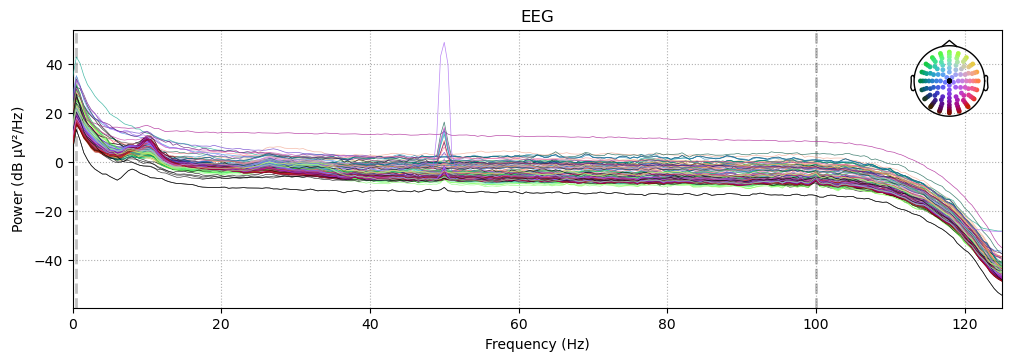

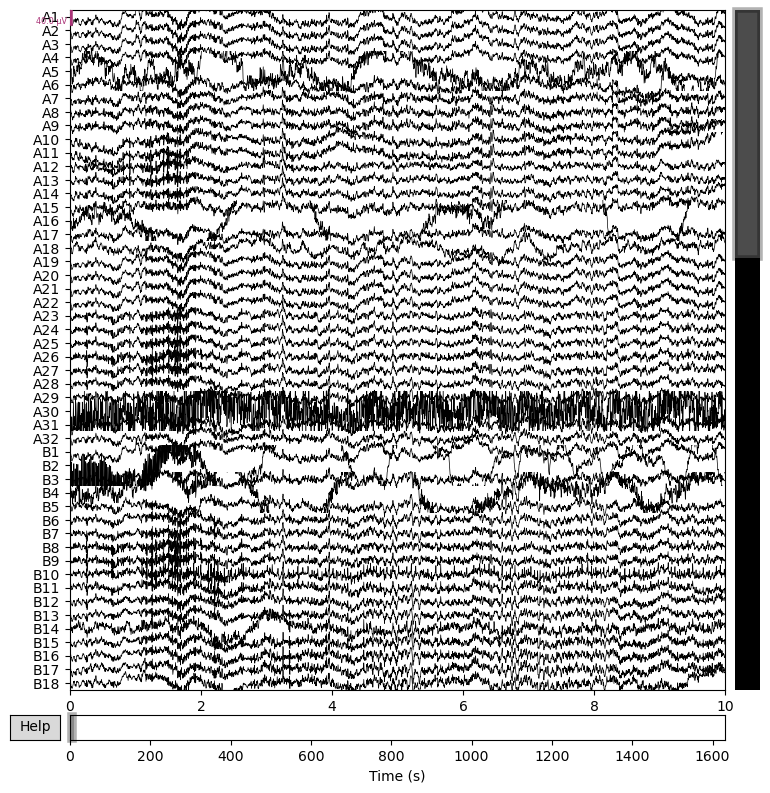

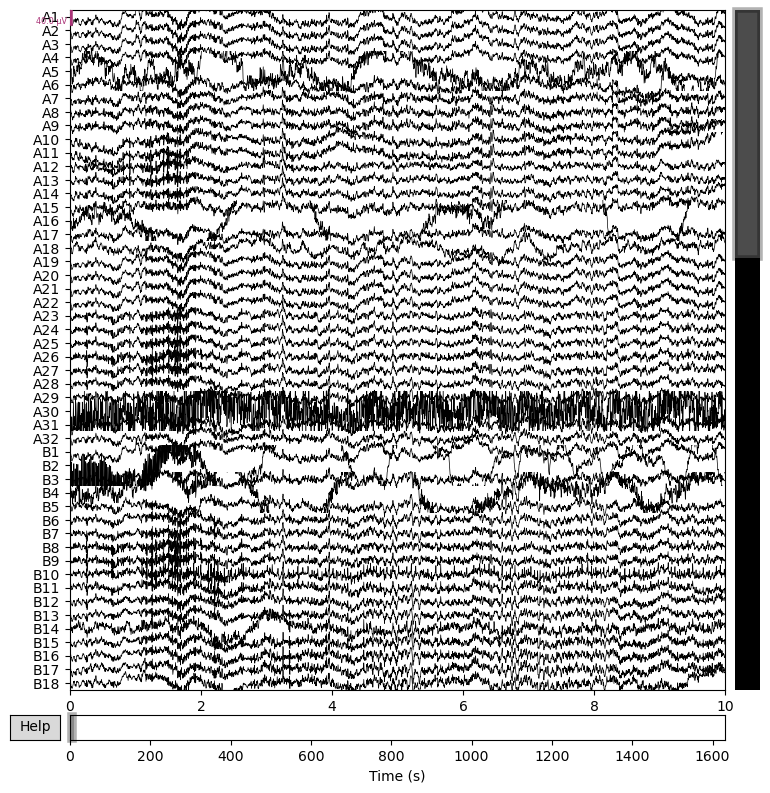

In [20]:
raw_notch.plot(n_channels=50, title='Filtered EEG Data (50 Hz)', show=True)

Effective window size : 2.000 (s)
Plotting power spectral density (dB=True).


C:\Users\windows\anaconda3\Lib\site-packages\mne\viz\utils.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


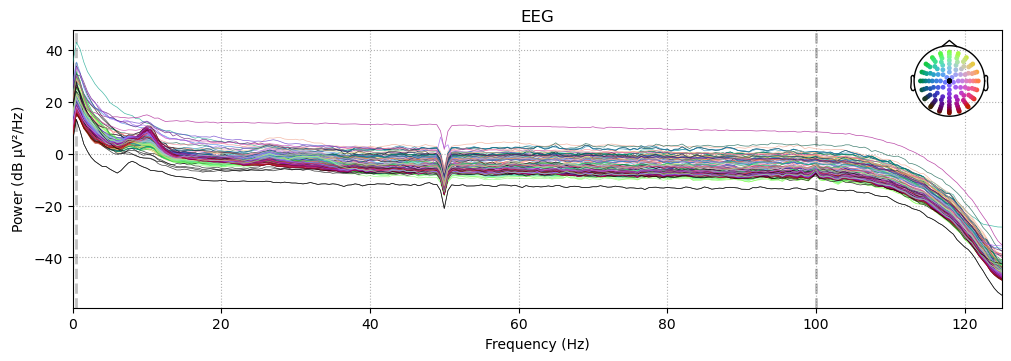

In [21]:
psd = raw_notch.compute_psd(fmax=125)
psd.plot()

In [22]:
# Sampling rate 출력
print(f"Sampling rate: {raw_notch.info['sfreq']} Hz")

Sampling rate: 1024.0 Hz


In [23]:
# Resampling
raw_resample = raw_notch.resample(sfreq=256)
raw_resample

Trigger channel Status has a non-zero initial value of 65536 (consider using initial_event=True to detect this event)
Removing orphaned offset at the beginning of the file.
1044 events found on stim channel Status
Event IDs: [11 12 13 14 15 16 17 21 22 23 31 32 33 34 42 44 45 46 51 61 62 63 64]
Trigger channel Status has a non-zero initial value of 65536 (consider using initial_event=True to detect this event)
Removing orphaned offset at the beginning of the file.
1044 events found on stim channel Status
Event IDs: [11 12 13 14 15 16 17 21 22 23 31 32 33 34 42 44 45 46 51 61 62 63 64]


<RawEDF | sub-02_ses-01_task-innerspeech_eeg.bdf, 137 x 417536 (1631.0 s), ~436.6 MiB, data loaded>

In [24]:
# Resampling 후 events 잘 변환되었는지 확인
events_resampled = mne.find_events(raw_resample, shortest_event=1)

print("Original events shape:", events.shape)
print("Resampled events shape:", events_resampled.shape)

print("Original events sample points (first 10):", events[:10,0])
print("Resampled events sample points (first 10):", events_resampled[:10,0])

Trigger channel Status has a non-zero initial value of 65536 (consider using initial_event=True to detect this event)
Removing orphaned offset at the beginning of the file.
1044 events found on stim channel Status
Event IDs: [11 12 13 14 15 16 17 21 22 23 31 32 33 34 42 44 45 46 51 61 62 63 64]
Original events shape: (1044, 3)
Resampled events shape: (1044, 3)
Original events sample points (first 10): [ 8394 18702 34080 38243 38274 41434 41997 42560 45171 46247]
Resampled events sample points (first 10): [ 2098  4675  8520  9560  9568 10358 10499 10640 11292 11561]


In [25]:
print(f"Sampling rate: {raw_resample.info['sfreq']} Hz")

Sampling rate: 256.0 Hz


In [26]:
# Epoching
event_id = {'arriba': 31, 'abajo': 32, 'derecha': 33, 'izquierda': 34}

# EEG 채널만 선택한 epoch 생성
exg_names = ['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8']
eeg_names = [ch for ch in raw_resample.ch_names if ch not in exg_names]

eeg = raw_resample.copy().pick_channels(eeg_names)

epochs = mne.Epochs(eeg, events, event_id=event_id, tmin=0, tmax=4.5,
                    baseline=None, preload=True, reject=None, flat=None, reject_by_annotation=False)

NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Not setting metadata
200 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 200 events and 1153 original time points ...
150 bad epochs dropped


In [27]:
print(epochs._data.shape)

(50, 129, 1153)


In [ ]:
# ICA
ica = ICA(n_components=128, random_state=97, method='infomax', fit_params=dict(extended=True))
ica.fit(epochs)

# ICA 컴포넌트 자동 라벨링
ic_labels = label_components(epochs, ica, method='iclabel')  # eeg 또는 epochs 사용 가능

labels = ic_labels["labels"]

# 2. brain과 other 외 컴포넌트는 artifact로 판단해 제외
exclude_idx = [idx for idx, label in enumerate(labels) if label not in ['brain', 'other']]

ica.exclude = exclude_idx

# 3. 제외된 컴포넌트 시각화 (확인용)
ica.plot_components()

# 4. ICA 적용해 artifact 제거한 epoch 생성
clean_epochs = ica.apply(epochs.copy())

# 5. 결과 확인용 PSD 그리기
clean_epochs.compute_psd().plot()

Fitting ICA to data using 128 channels (please be patient, this may take a while)
Selecting by number: 128 components
Computing Extended Infomax ICA


In [ ]:
# Epoch 개수 확인
print(f"Total number of epochs: {len(clean_epochs)}")

In [ ]:
# 저장 파일 경로 생성
save_path = f"{base_path}/{subject}_ses-01_eeg-epo.fif"

In [ ]:
# clean_epochs를 파일로 저장
clean_epochs.save(file_path, overwrite=True)